In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the 'taxis' dataset
df = sns.load_dataset("taxis")

In [3]:
# 1. Check for missing values in the dataset[cite: 1]
print("Missing values per column before handling:")
print(df.isnull().sum())

# 2. Impute missing values based on column type[cite: 1]
# Numerical columns: Impute with median
num_cols = df.select_dtypes(include=['float64', 'int64']).columns
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Categorical columns: Impute with mode
cat_cols = ['payment', 'color']
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# 3. Drop rows where critical location columns (borough/zone) are missing[cite: 1]
df.dropna(subset=['pickup_borough', 'dropoff_borough', 'pickup_zone', 'dropoff_zone'], inplace=True)

print("\nMissing values after handling:")
print(df.isnull().sum())

Missing values per column before handling:
pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

Missing values after handling:
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


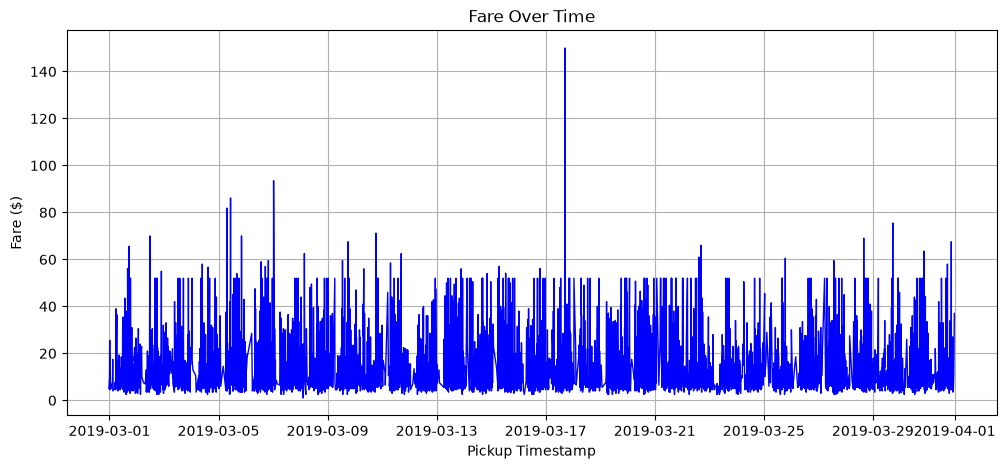

In [5]:
# Convert pickup column to datetime format
df['pickup'] = pd.to_datetime(df['pickup'])

# Sort by pickup timestamp for line plotting
df_sorted = df.sort_values('pickup')

plt.figure(figsize=(12, 5))
plt.plot(df_sorted['pickup'], df_sorted['fare'], color='blue', linewidth=1)
plt.title('Fare Over Time')
plt.xlabel('Pickup Timestamp')
plt.ylabel('Fare ($)')
plt.grid(True)
plt.show()

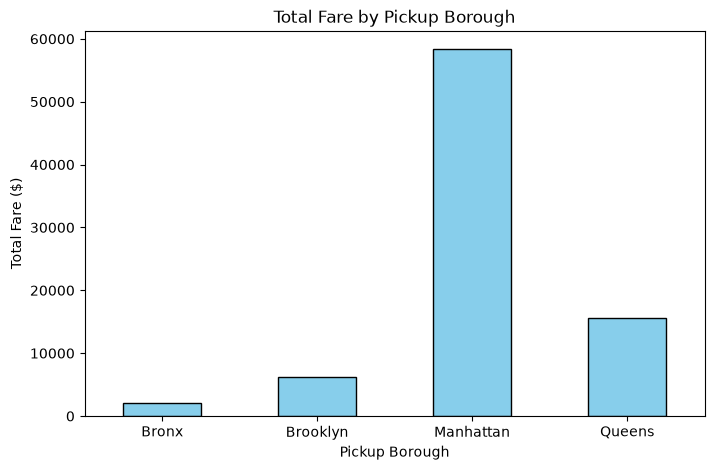

In [6]:
# Group by pickup_borough and sum the fare
total_fare_by_borough = df.groupby('pickup_borough')['fare'].sum()

plt.figure(figsize=(8, 5))
total_fare_by_borough.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare ($)')
plt.xticks(rotation=0)
plt.show()

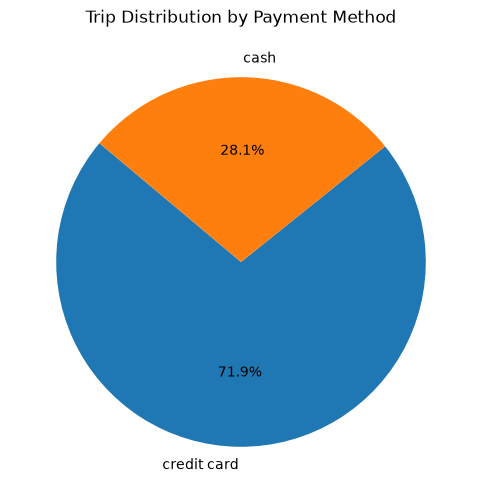

In [7]:
payment_counts = df['payment'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(payment_counts, labels=payment_counts.index, autopct='%1.1f%%', startangle=140)
plt.title('Trip Distribution by Payment Method')
plt.show()

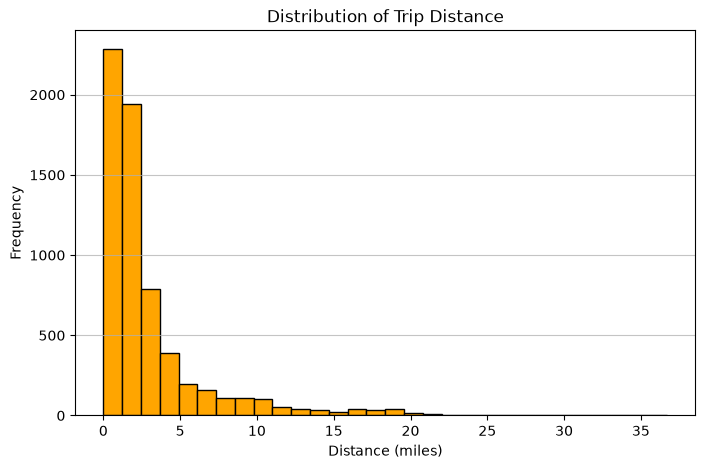

In [8]:
plt.figure(figsize=(8, 5))
plt.hist(df['distance'], bins=30, color='orange', edgecolor='black')
plt.title('Distribution of Trip Distance')
plt.xlabel('Distance (miles)')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()

<Figure size 800x500 with 0 Axes>

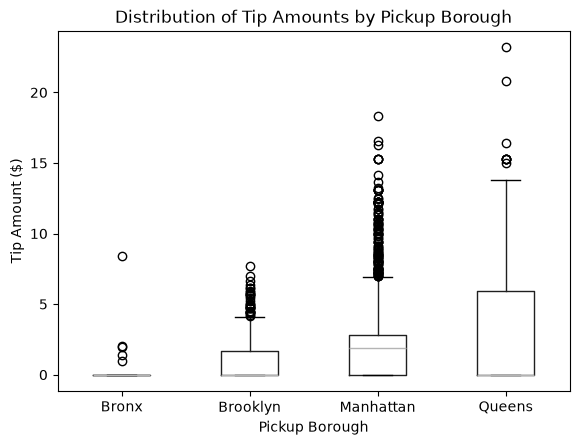

In [9]:
plt.figure(figsize=(8, 5))
df.boxplot(column='tip', by='pickup_borough', grid=False)
plt.title('Distribution of Tip Amounts by Pickup Borough')
plt.suptitle('')  # Removes automatic pandas subplot title
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount ($)')
plt.show()

C:\Users\asust\AppData\Local\Temp\ipykernel_28408\3830537032.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='pickup_borough', palette='viridis')


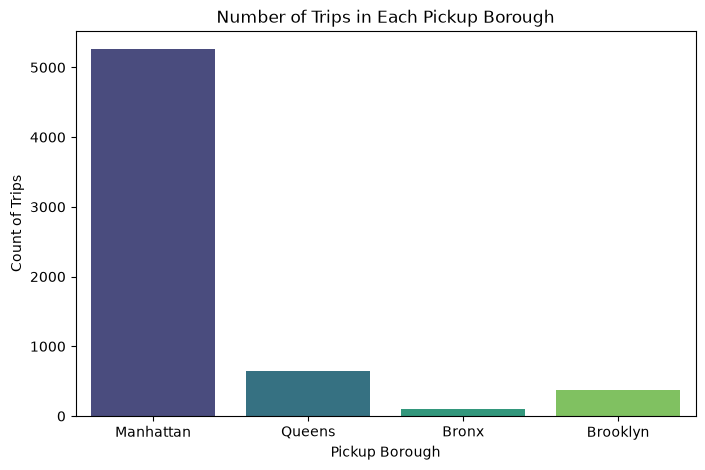

In [10]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='pickup_borough', palette='viridis')
plt.title('Number of Trips in Each Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Count of Trips')
plt.show()

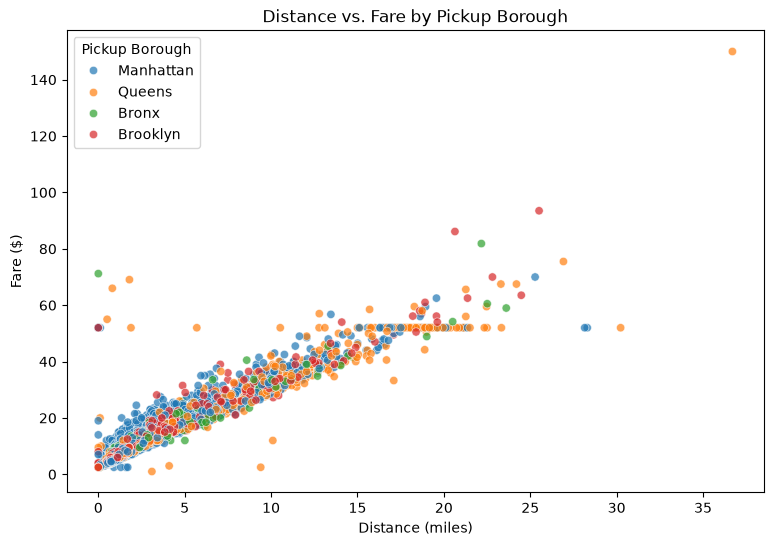

In [11]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='distance', y='fare', hue='pickup_borough', alpha=0.7)
plt.title('Distance vs. Fare by Pickup Borough')
plt.xlabel('Distance (miles)')
plt.ylabel('Fare ($)')
plt.legend(title='Pickup Borough')
plt.show()

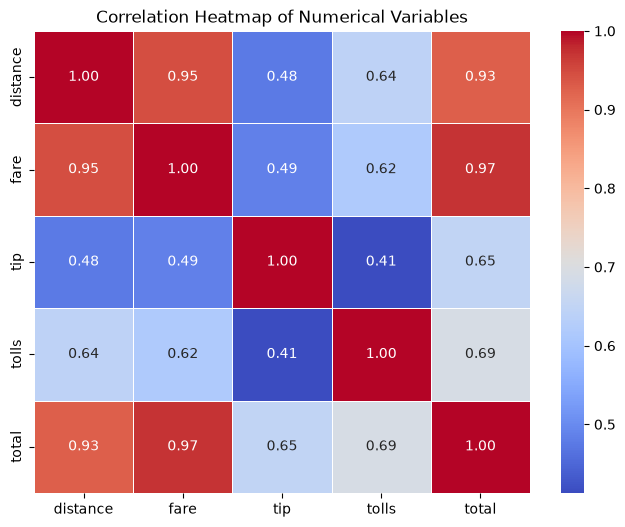

In [13]:
# Select numerical variables for correlation matrix
numerical_df = df[['distance', 'fare', 'tip', 'tolls', 'total']]
corr_matrix = numerical_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Variables')
plt.show()

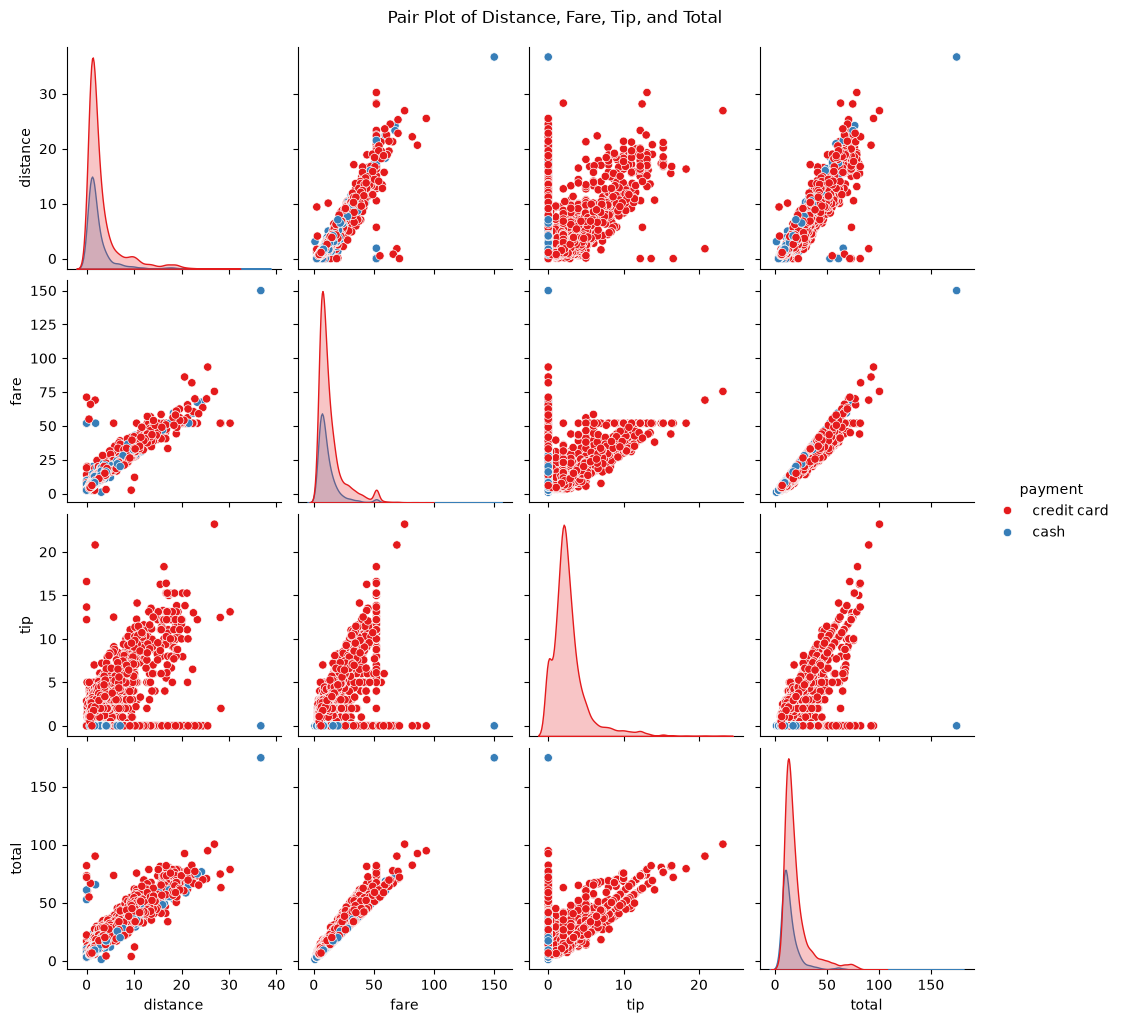

In [14]:
# Pair plot comparing distance, fare, tip, total colored by payment or zone
sns.pairplot(df[['distance', 'fare', 'tip', 'total', 'payment']], hue='payment', palette='Set1')
plt.suptitle('Pair Plot of Distance, Fare, Tip, and Total', y=1.02)
plt.show()

C:\Users\asust\AppData\Local\Temp\ipykernel_28408\1537771482.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='payment', y='fare', palette='muted')


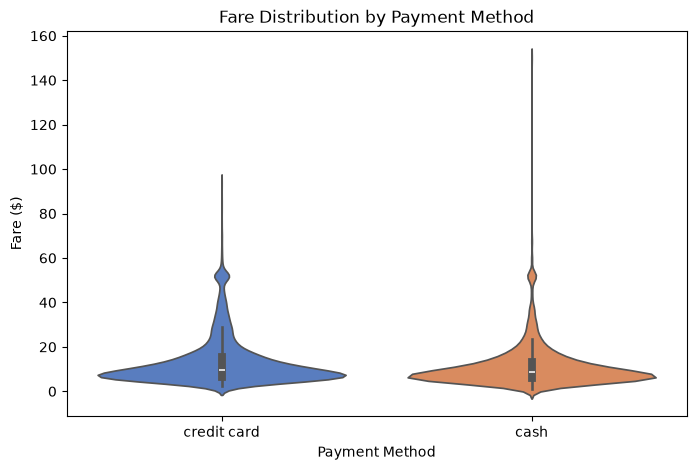

In [15]:
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x='payment', y='fare', palette='muted')
plt.title('Fare Distribution by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare ($)')
plt.show()